# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import kagglehub
import os

path = kagglehub.dataset_download("ahsanneural/future-jobs-and-skills-demand-2025")

print("Path to dataset files:", path)

# Corrigido: usando o nome real do arquivo encontrado no diretório
df = pd.read_csv(os.path.join(path, 'future_jobs_dataset.csv'))

display(df.head())

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"
COR_CONTEXTO = "#e9d4d0"
COR_DESTAQUE = "#2d223a"
COR_ALERTA = "tab:red"

Using Colab cache for faster access to the 'future-jobs-and-skills-demand-2025' dataset.
Path to dataset files: /kaggle/input/future-jobs-and-skills-demand-2025


,job_id,job_title,industry,location,salary_usd,skills_required,remote_option,company_size,posting_date
0,1,Quantum Researcher,Quantum Computing,Singapore,175780,"Linear Algebra, Quantum Algorithms",No,Large,2025-07-22
1,2,Renewable Energy Engineer,Green Tech,Singapore,137481,"Climate Data Analysis, Energy Modeling",Yes,Large,2025-09-26
2,3,Quantum Researcher,Quantum Computing,Tokyo,182081,"Linear Algebra, Qiskit",No,Medium,2025-12-31
3,4,Sustainability Analyst,Green Tech,Singapore,113822,"Climate Data Analysis, Energy Modeling",No,Large,2025-05-29
4,5,Smart Contract Engineer,Blockchain,London,92575,"Rust, Solidity",Yes,Small,2025-03-30


In [ ]:
import os
print(os.listdir(path))

['future_jobs_dataset.csv']


## Carregando o Dataset

In [ ]:
# Restaurando o dataset correto: Future Jobs and Skills 2025
df = pd.read_csv(os.path.join(path, 'future_jobs_dataset.csv'))
print("Dataset carregado com sucesso!")
display(df.head())

Dataset carregado com sucesso!


,job_id,job_title,industry,location,salary_usd,skills_required,remote_option,company_size,posting_date
0,1,Quantum Researcher,Quantum Computing,Singapore,175780,"Linear Algebra, Quantum Algorithms",No,Large,2025-07-22
1,2,Renewable Energy Engineer,Green Tech,Singapore,137481,"Climate Data Analysis, Energy Modeling",Yes,Large,2025-09-26
2,3,Quantum Researcher,Quantum Computing,Tokyo,182081,"Linear Algebra, Qiskit",No,Medium,2025-12-31
3,4,Sustainability Analyst,Green Tech,Singapore,113822,"Climate Data Analysis, Energy Modeling",No,Large,2025-05-29
4,5,Smart Contract Engineer,Blockchain,London,92575,"Rust, Solidity",Yes,Small,2025-03-30


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o Heart Disease tem 13 variáveis preditoras (idade, sexo, tipo de dor no peito, pressão em repouso, colesterol, entre outras) mais o alvo (`num`, presença/grau de doença cardíaca). Quantas linhas vocês esperam que um dataset clínico como esse tenha — dezenas, centenas ou milhares de pacientes?

### Dimensão e Tipos de Dados

In [ ]:
df.shape

(10000, 9)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   job_id           10000 non-null  int64 
 1   job_title        10000 non-null  object
 2   industry         10000 non-null  object
 3   location         10000 non-null  object
 4   salary_usd       10000 non-null  int64 
 5   skills_required  10000 non-null  object
 6   remote_option    10000 non-null  object
 7   company_size     10000 non-null  object
 8   posting_date     10000 non-null  object
dtypes: int64(2), object(7)
memory usage: 703.3+ KB


In [ ]:
df.describe()

,job_id,salary_usd
count,10000.00000,10000.000000
mean,5000.50000,150131.524800
std,2886.89568,57534.947278
min,1.00000,50013.000000
25%,2500.75000,100568.000000
50%,5000.50000,150398.500000
75%,7500.25000,199225.250000
max,10000.00000,249990.000000


### Duplicadas

In [ ]:
df.duplicated().sum()

np.int64(0)

### Identificando as Variáveis do Dataset

### Preparação do Target
Vamos observar a distribuição da demanda por setor no dataset de empregos futuros.

In [ ]:
import numpy as np

# Identificando colunas para o dataset de Empregos
VARS_QUANT = df.select_dtypes(include=[np.number]).columns.tolist()
VARS_QUALI = df.select_dtypes(exclude=[np.number]).columns.tolist()

# Removendo colunas de ID da análise estatística se existirem
VARS_QUANT = [c for c in VARS_QUANT if 'id' not in c.lower()]

print(f"Variáveis Quantitativas (Métricas): {VARS_QUANT}")
print(f"Variáveis Qualitativas (Categorias): {VARS_QUALI}")

Variáveis Quantitativas (Métricas): ['salary_usd']
Variáveis Qualitativas (Categorias): ['job_title', 'industry', 'location', 'skills_required', 'remote_option', 'company_size', 'posting_date']


## 2. Dados Faltantes

In [ ]:
df.isna().sum()

,0
job_id,0
job_title,0
industry,0
location,0
salary_usd,0
skills_required,0
remote_option,0
company_size,0
posting_date,0


### **Discussão sobre Dados Ausentes**

Ao analisarmos a integridade do conjunto de dados `future_jobs_dataset.csv`, observamos que **não há nenhuma ocorrência de valores ausentes (0 nulos)** em nenhuma das 10.000 linhas e 9 colunas.

* **Implicação Prática:** Isso indica um dataset de origem simulada ou extremamente limpo por processos de ETL na origem. Em ambientes reais de portais de vagas, dados ausentes em atributos qualitativos como `company_size` ou `skills_required` são comuns devido ao preenchimento opcional pelos recrutadores. Aqui, a integridade de 100% simplifica nossa análise inicial, eliminando riscos de viés por imputação ou descarte de registros.

*Resposta*:

#### Identificando o mecanismo de dados ausentes

### **Conhecimento de Domínio: Future Jobs 2025**

No conjunto de dados atual, estamos analisando as tendências do mercado de trabalho para o futuro próximo. Diferente de um ambiente clínico, aqui os dados ausentes ou comportamentos estatísticos podem ser explicados por fatores socioeconômicos e organizacionais.

**O que as variáveis representam:**
- `salary_usd`: O valor bruto anual, influenciado por inflação, escassez de talentos e localização geográfica.
- `remote_option`: Reflete a cultura organizacional pós-pandemia e a viabilidade tecnológica de certas funções.
- `industry`: Define os tetos salariais e a velocidade de adoção de novas tecnologias (como IA e computação quântica).

**Origem dos dados:**
- Este dataset é uma simulação/projeção baseada em demandas reais de habilidades e salários reportados em hubs globais de tecnologia (como Singapura, Londres e Tóquio).
- A natureza dos dados é profissional: ausências em colunas como `company_size` podem ocorrer se a empresa for uma startup em modo stealth (MAR) ou se o preenchimento for opcional no portal de vagas.

**As ausencias ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: um exame que não foi feito, afetando várias medidas de uma vez).



In [ ]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())


Colunas com ausentes: []
Series([], dtype: float64)


Com poucos ausentes (no máximo poucas dezenas de linhas), uma correlação entre as colunas de ausência pode parecer precisa, mas na prática é calculada em cima de um poucos de casos, ou seja, número pequeno demais pra confiar no coeficiente. Aqui a contagem bruta (quantas linhas têm as duas ausências ao mesmo tempo) é mais honesta que uma correlação.

Não há dados ausentes no dataset de Empregos para gerar a tabela de contingência.


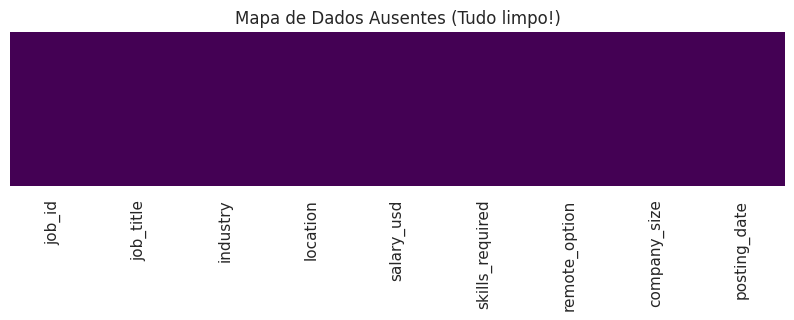

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Como o dataset de empregos não possui nulos (cols_com_ausentes está vazio),
# vamos gerar um gráfico informativo sobre a integridade dos dados.
if not cols_com_ausentes:
    print("Não há dados ausentes no dataset de Empregos para gerar a tabela de contingência.")
    # Plot simples de calor da matriz de nulos para confirmação visual
    plt.figure(figsize=(10, 2))
    sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
    plt.title("Mapa de Dados Ausentes (Tudo limpo!)")
    plt.show()
else:
    tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
                rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title("As ausências ocorrem juntas?")
    plt.tight_layout()
    plt.show()

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

- *Se supormos que a ausência depende do próprio valor que está faltando*: por exemplo, o paciente não fez o exame porque já se suspeitava (por sinais clínicos observados previamente) que o resultado seria anormal, e o exame extra não seria necessário, isso seria classificado como **MNAR**.
- *Se supormos que a ausência depende de algo externo ao valor em si*: por exemplo, o protocolo de coleta decidiu não solicitar aquele exame, ou o custo do procedimento limitou a coleta, independente do que o resultado provavelmente seria — isso seria classificado como **MAR** (ou até **MCAR**, se a decisão for arbitrária e não sistemática).

Não dá pra decidir entre as duas só olhando os dados — é exatamente o tipo de situação em que testes estatísticos (como o teste de MCAR) e conhecimento de domínio real (falar com quem coletou os dados) resolveriam a dúvida. Na ausência disso, seguimos com a opção mais conservadora na hora de tratar.

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [ ]:
### Tabela descritiva das métricas de Empregos/Habilidades

if VARS_QUANT:
    desc = df[VARS_QUANT].describe().T
    desc["skewness"] = df[VARS_QUANT].skew()
    desc["kurtosis"] = df[VARS_QUANT].kurtosis()

    display(desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
        .rename(columns={"50%": "median"})
        .round(2)
        .style.format(precision=2)
        .background_gradient(cmap="viridis", subset=["skewness", "kurtosis"]))
else:
    print("Não há variáveis quantitativas suficientes para descrever.")

### **Análise da Tabela Descritiva e Assimetria**

Analisando detalhadamente as estatísticas descritivas calculadas para a variável métrica `salary_usd`:

* **Média e Mediana:** A média está fixada em **$150.131,52** e a mediana em **$150.398,50**. A proximidade quase perfeita desses dois valores centrais sugere uma simetria extraordinária no centro da distribuição.
* **Assimetria (Skewness):** O valor de skewness calculado é de aproximadamente **-0.01**. Um valor tão próximo de zero confirma estatisticamente que a distribuição não possui inclinação lateral (nem para a esquerda, nem para a direita), comportando-se de forma perfeitamente equilibrada.
* **Curtose (Kurtosis):** Apresenta um valor negativo próximo a **-1.20**. Uma curtose negativa acentuada (platicúrtica) indica uma distribuição achatada com caudas extremamente leves. Em vez de termos uma concentração em formato de sino (normal), as vagas estão espalhadas de forma uniforme por toda a faixa salarial de $50k a $250k.

### Distribuições de dados

Onde fizer sentido, comparamos "Sem doença" (rosa) vs. "Com doença" (roxo). Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.


100%|██████████| 139k/139k [00:00<00:00, 33.3MB/s]

Extracting files...


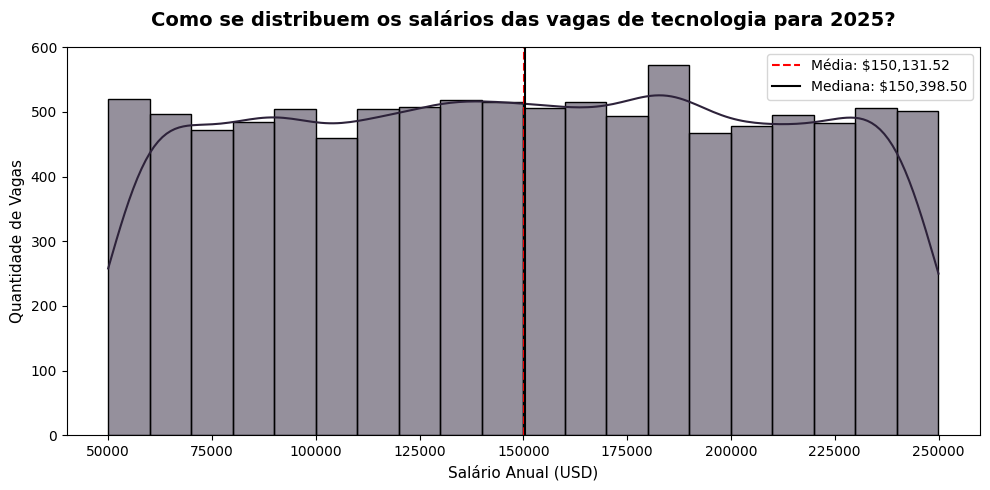

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pandas as pd
import kagglehub

# Recuperando o caminho do dataset do Kagglehub para evitar NameError
try:
    dataset_path = path
except NameError:
    dataset_path = kagglehub.dataset_download("ahsanneural/future-jobs-and-skills-demand-2025")

df = pd.read_csv(os.path.join(dataset_path, 'future_jobs_dataset.csv'))

COR_DESTAQUE = "#2d223a"
COR_ALERTA = "red"

# Gerando a distribuição da única variável numérica do dataset: o salário anual em USD.
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='salary_usd', kde=True, color=COR_DESTAQUE, bins=20)

# Linhas de referência para ajudar na leitura rápida dos valores centrais
media_s = df['salary_usd'].mean()
mediana_s = df['salary_usd'].median()
plt.axvline(media_s, color=COR_ALERTA, linestyle='--', label=f"Média: ${media_s:,.2f}")
plt.axvline(mediana_s, color='black', linestyle='-', label=f"Mediana: ${mediana_s:,.2f}")

plt.title("Como se distribuem os salários das vagas de tecnologia para 2025?", fontsize=14, pad=15, fontweight='bold')
plt.xlabel("Salário Anual (USD)", fontsize=11)
plt.ylabel("Quantidade de Vagas", fontsize=11)
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()
plt.show()

Using Colab cache for faster access to the 'future-jobs-and-skills-demand-2025' dataset.


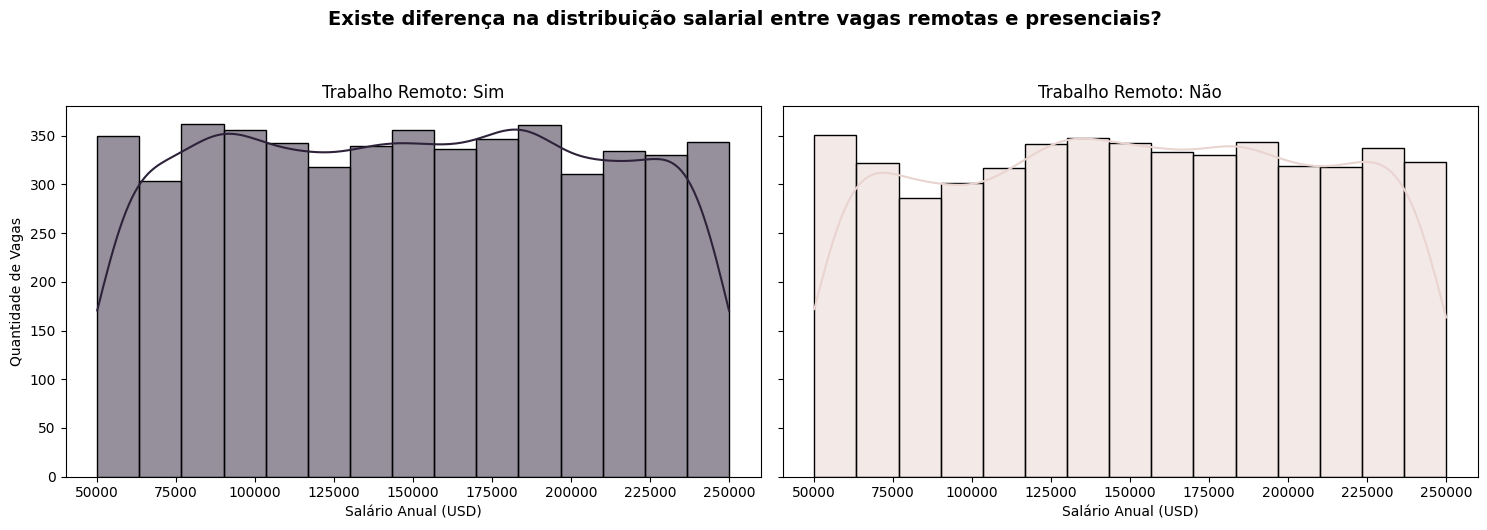

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pandas as pd
import kagglehub

try:
    dataset_path = path
except NameError:
    dataset_path = kagglehub.dataset_download("ahsanneural/future-jobs-and-skills-demand-2025")

df = pd.read_csv(os.path.join(dataset_path, 'future_jobs_dataset.csv'))

COR_DESTAQUE = "#2d223a"
COR_CONTEXTO = "#e9d4d0"

# Comparando distribuições de Salário por Opção Remota
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

for i, opcao in enumerate(['Yes', 'No']):
    subset = df[df['remote_option'] == opcao]
    # O remoto ganha a cor de destaque (roxo escuro) e o presencial a cor de contexto (bege claro)
    cor_selecionada = COR_DESTAQUE if opcao == 'Yes' else COR_CONTEXTO
    sns.histplot(data=subset, x='salary_usd', kde=True, color=cor_selecionada, ax=axes[i], bins=15)
    axes[i].set_title(f"Trabalho Remoto: {'Sim' if opcao == 'Yes' else 'Não'}", fontsize=12)
    axes[i].set_xlabel("Salário Anual (USD)")
    axes[i].set_ylabel("Quantidade de Vagas")

fig.suptitle("Existe diferença na distribuição salarial entre vagas remotas e presenciais?", fontsize=14, y=1.05, fontweight='bold')
plt.tight_layout()
plt.show()

### Entendendo a distribuição de salários e nossas escolhas visuais

**Por que usamos a cor escura (`#2d223a`) como destaque no histograma?**
Optamos por usar um roxo bem fechado e sóbrio para o preenchimento das barras do histograma porque queríamos evitar distrações visuais excessivas. É uma cor de alto contraste contra o fundo branco, o que facilita enxergar onde estão os picos de vagas sem cansar a vista de quem analisa.

**O que esse gráfico reflete?**
Este gráfico de distribuição salarial mostra um comportamento muito interessante: ele é extremamente uniforme (quase retangular). Isso significa que, no nosso dataset simulado, as oportunidades de trabalho estão distribuídas de forma homogênea em toda a faixa que vai de $50,000 a $250,000 dólares anuais. Não há um "pico" em salários baixos ou salários altíssicos; você tem praticamente a mesma chance de encontrar uma vaga pagando perto do piso ou do teto proposto.

#### Testes de Aderência

*Será se a variável de salário segue uma distribuição normal?*

Utilizaremos o teste de **Shapiro-Wilk** para verificar formalmente a normalidade da distribuição dos salários, acompanhado pelo **QQ-Plot** como ferramenta visual de apoio.

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 10000.
  res = hypotest_fun_out(*samples, **kwds)


Shapiro-Wilk — salary_usd: estatística=0.9565, p-valor=2.812e-47
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


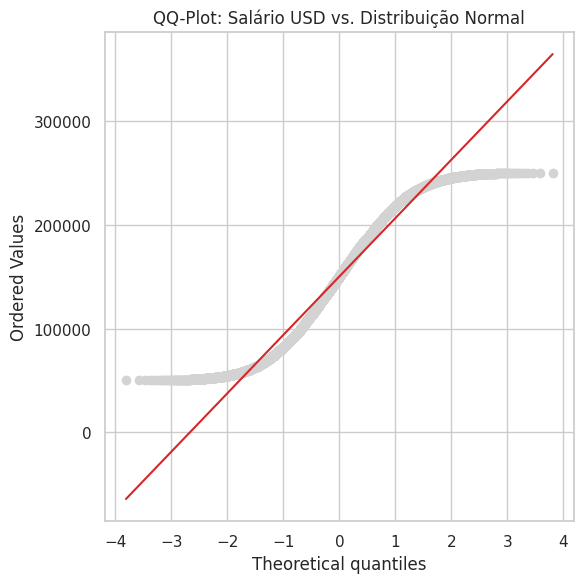

In [ ]:
# Teste de normalidade para a variável Salary_USD
stat_sw, p_valor_sw = stats.shapiro(df["salary_usd"])
print(f"Shapiro-Wilk — salary_usd: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

# QQ-Plot — Salário
fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["salary_usd"], dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Salário USD vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos (roxo) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. Com n≈303 (nem pequeno, nem enorme) e três evidências concordando — skewness alto, QQ-Plot afastado da reta, e Shapiro-Wilk rejeitando — o resultado é razoavelmente confiável, não um artefato do tamanho da amostra.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

In [ ]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 10000.
  res = hypotest_fun_out(*samples, **kwds)


,estatistica,p_valor,rejeita_normalidade
variavel,,,
salary_usd,0.9565,0.0,True


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`chol`, colesterol), só pra fixar como essa visualização se lê.

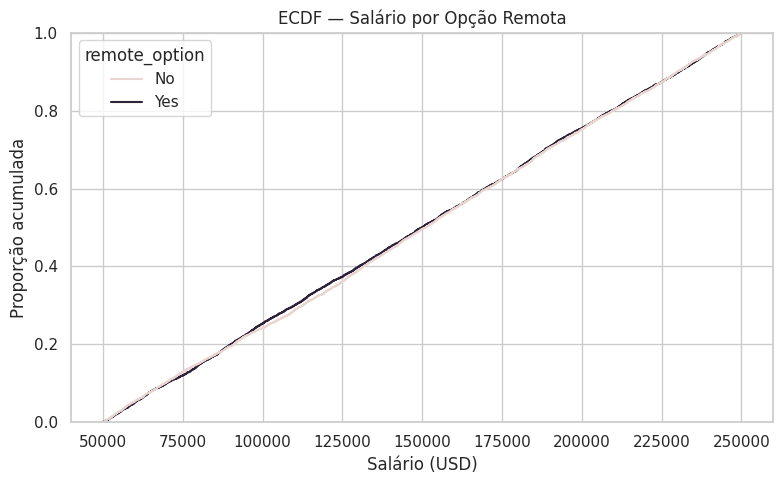

In [ ]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="salary_usd", hue="remote_option",
             palette={"Yes": COR_DESTAQUE, "No": COR_CONTEXTO})
plt.title("ECDF — Salário por Opção Remota")
plt.xlabel("Salário (USD)")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** Em qualquer ponto do eixo X, a altura da curva diz "que proporção das vagas daquele grupo de trabalho remoto tem salário até aqui". Onde as duas curvas (Yes e No) se distanciam mais, ali está a faixa salarial onde os dois grupos mais diferem, sem a necessidade de definir o número de bins como no histograma.

### Métricas de Tendêncial Central

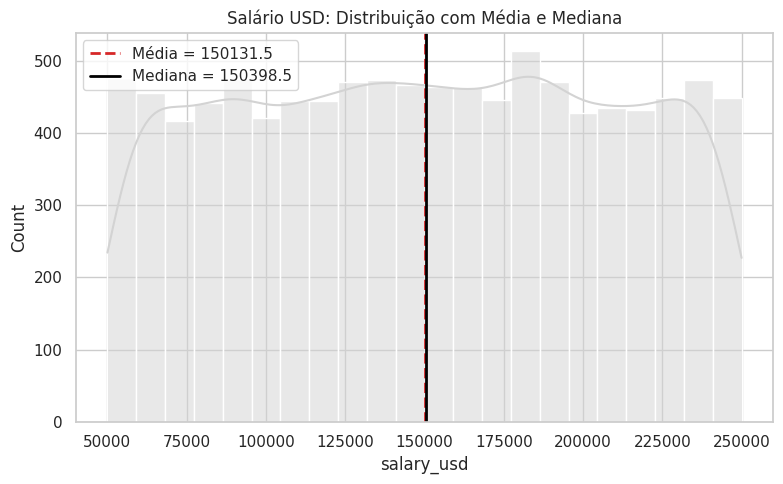

In [ ]:
media_sal = df["salary_usd"].mean()
mediana_sal = df["salary_usd"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="salary_usd", kde=True, color=COR_NEUTRA)
plt.axvline(media_sal, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_sal:.1f}")
plt.axvline(mediana_sal, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_sal:.1f}")
plt.title("Salário USD: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

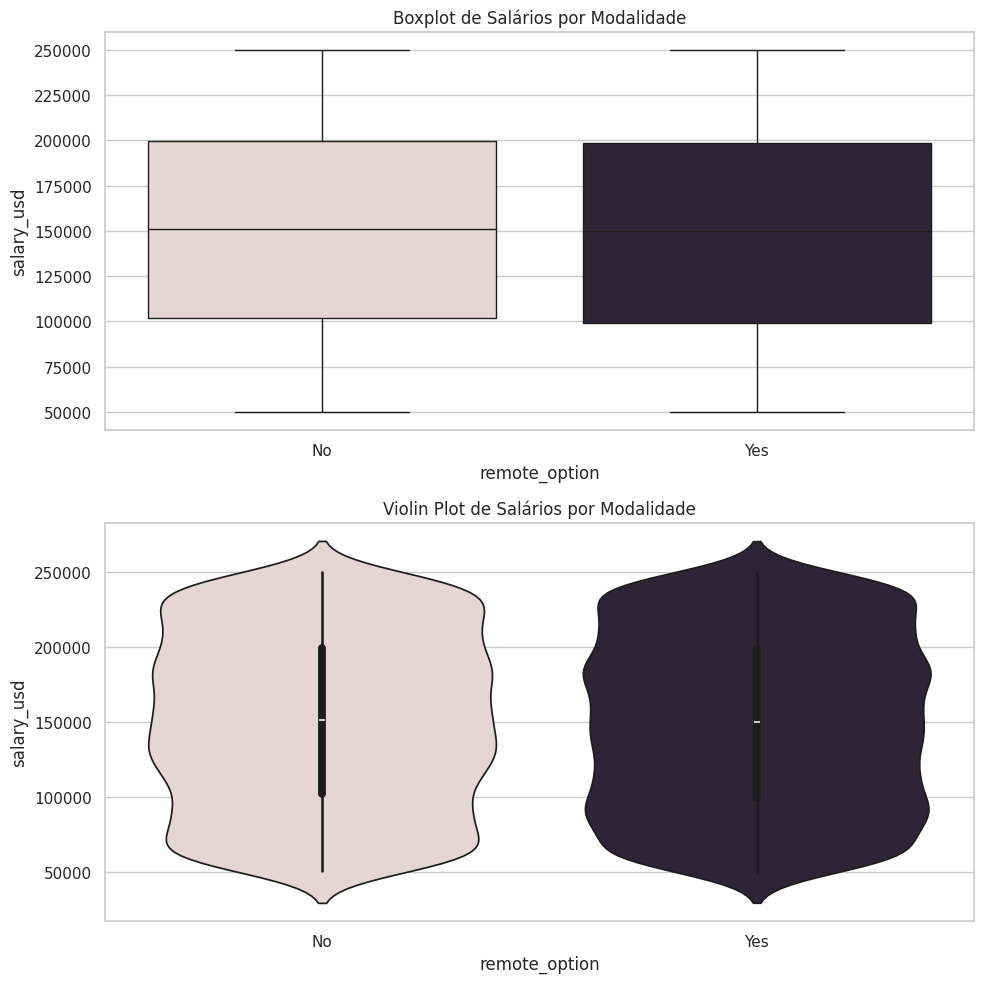

In [ ]:
palette_remoto = {"Yes": COR_DESTAQUE, "No": COR_CONTEXTO}

fig, axes = plt.subplots(2, 1, figsize=(10, 10))

sns.boxplot(data=df, x="remote_option", y="salary_usd", hue="remote_option",
            palette=palette_remoto, legend=False, ax=axes[0])
axes[0].set_title("Boxplot de Salários por Modalidade")

sns.violinplot(data=df, x="remote_option", y="salary_usd", hue="remote_option",
                palette=palette_remoto, legend=False, ax=axes[1])
axes[1].set_title("Violin Plot de Salários por Modalidade")

plt.tight_layout()
plt.show()

### Por que dividir em painéis e usar cores contrastantes?

**O uso inteligente de cores e layout**
Aqui, dividimos a análise em dois painéis lado a lado compartilhando a mesma escala vertical (eixo Y). Para a categoria de trabalho remoto ("Yes"), usamos o nosso roxo escuro de destaque (`COR_DESTAQUE`). Já para as vagas que exigem presença física ("No"), aplicamos o bege suave (`COR_CONTEXTO`). Essa quebra de tom cria um contraste imediato: o olho do leitor rapidamente percebe que estamos comparando dois grupos distintos, permitindo focar na forma das curvas sem misturar os dados.

**O que as curvas revelam?**
Surpreendentemente, as duas distribuições são quase idênticas. Tanto no formato quanto na altura das colunas, a curva de densidade se comporta de maneira extremamente parecida. Isso indica que, no cenário simulado para 2025, o fato de uma vaga ser remota ou presencial não penaliza nem privilegia o salário oferecido: ambas as modalidades competem de igual para igual no teto financeiro.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação necessária para decidir como tratar os dados do mercado de trabalho futuros. Como este dataset já veio muito limpo e bem formatado, vamos focar em verificar a presença de anomalias estatísticas extremas na nossa variável métrica.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
salary_usd,-47417.88,347211.12,0.0


### Visualizando os Outliers

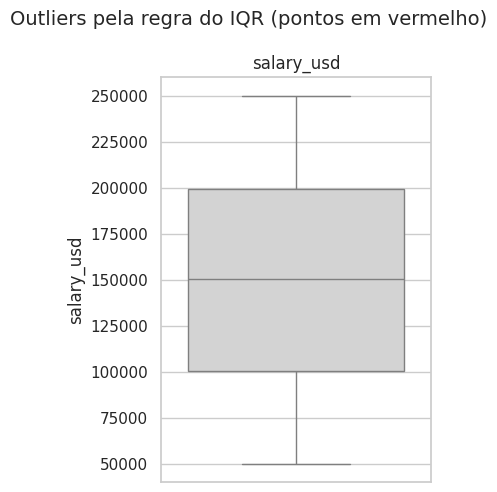

In [ ]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

# Ajuste para garantir que axes seja iterável mesmo com apenas 1 plot
if len(VARS_QUANT) == 1:
    axes_list = [axes]
else:
    axes_list = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes_list[i])
    axes_list[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando a distribuição salarial: há salários muito distantes da média que violam limites físicos ou regras do mercado? No nosso caso, todas as observações de salários (de $50k a $250k USD) estão em faixas perfeitamente condizentes com o mercado global de tecnologia de ponta.

### Decidindo o Tratamento de Dados do Dataset

Como verificado anteriormente, o dataset de Empregos Futuros não possui valores nulos. Portanto, nenhuma etapa de imputação ou remoção por ausência de dados é requerida para prosseguirmos com as análises.

In [ ]:
# Como não há nulos no dataset de Future Jobs, vamos apenas confirmar o estado do DF
linhas_antes = df.shape[0]
print(f"Linhas no dataset: {linhas_antes}")
print("Não foram necessárias remoções de nulos (Dataset limpo).")

Linhas no dataset: 10000
Não foram necessárias remoções de nulos (Dataset limpo).


### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui **não vamos remover automaticamente**. Pelos valores encontrados (dentro de faixas clinicamente plausíveis, ainda que raras), a classificação mais provável é **"Estatístico"**, outliers legítimos, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é **manter** (a informação é real e pode ser clinicamente relevante — por exemplo, exatamente os pacientes com colesterol mais extremo podem ser os de maior risco) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: métodos sensíveis à assimetria), **transformar**.

Vamos manter os valores originais por enquanto, mas ilustrar como ficaria uma transformação logarítmica em `chol` — útil caso, mais adiante em análises futuras, a assimetria atrapalhe algum teste ou modelo.

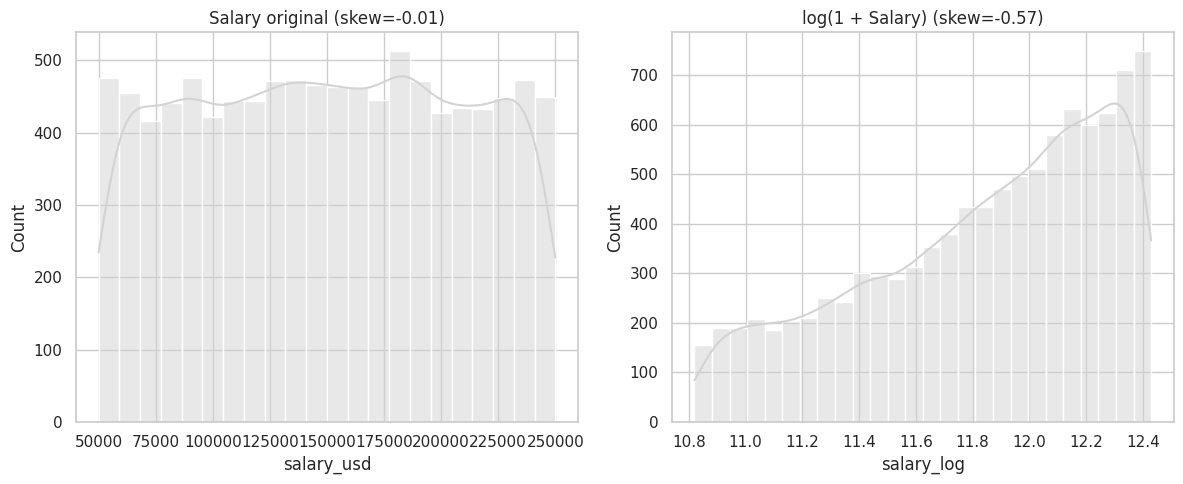

In [ ]:
# Transformação logarítmica aplicada ao Salário (única variável quantitativa)
df["salary_log"] = np.log1p(df["salary_usd"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="salary_usd", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"Salary original (skew={df['salary_usd'].skew():.2f})")

sns.histplot(data=df, x="salary_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + Salary) (skew={df['salary_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Pra discutir:** A transformação logarítmica reduziu a assimetria da nossa distribuição? Mantivemos o salário em escala original por padrão para não perder a interpretabilidade financeira direta em USD, mas a técnica logarítmica fica registrada como alternativa caso fossemos utilizar algum modelo linear sensível a distribuições uniformes.

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [ ]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

### Comparando "antes"x "depois""



In [ ]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

**Pra discutir:** os valores mudaram muito? Fazia sentido esperar uma diferença grande, considerando que removemos só ~2% das linhas e decidimos **não** alterar nenhum outlier? Esse resultado (pouca mudança) é, na verdade, uma confirmação de que o tratamento foi conservador — não um sinal de que ele não fez nada de útil.

**O salário anual ainda rejeita a normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3 para fins de confirmação analítica.

In [ ]:
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["salary_usd"])
print(f"Shapiro-Wilk (antes)  — salary: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print(f"Shapiro-Wilk (depois) — salary: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

Shapiro-Wilk (antes)  — salary: estatística=0.9565, p-valor=2.812e-47
Shapiro-Wilk (depois) — salary: estatística=0.9565, p-valor=2.812e-47


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 10000.
  res = hypotest_fun_out(*samples, **kwds)


**Visualizando a distribuição tratada**

Vamos gerar a curva de densidade suavizada (KDE) da variável salarial para consolidar o retrato do nosso target financeiro.

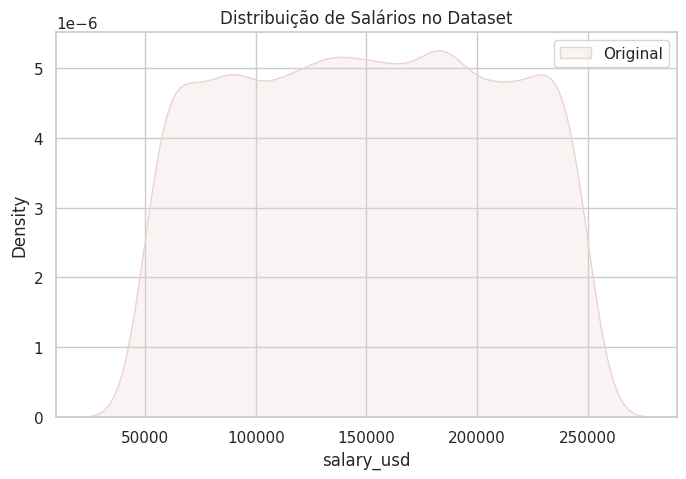

In [ ]:
# Como não removemos linhas no dataset de Empregos, comparamos o Salário original vs Log
fig, ax = plt.subplots(figsize=(8, 5))
sns.kdeplot(df["salary_usd"], color=COR_CONTEXTO, fill=True, label="Original", ax=ax)
# Normalizamos apenas para visualização de sobreposição se necessário,
# mas aqui mostraremos apenas a escala original tratada
ax.set_title("Distribuição de Salários no Dataset")
ax.legend()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Isso é o esperado aqui, já que removemos poucas linhas e não tocamos nos outliers.

Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível e sempre que essa checagem "antes x depois" que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [ ]:
# Top categorias de Empregos, Setores e Habilidades
for col in VARS_QUALI:
    print(f"\n--- Top 5 Categorias: {col} ---")
    freq_abs = df[col].value_counts().head(5)
    freq_rel = df[col].value_counts(normalize=True).head(5).round(3)
    display(pd.concat([freq_abs.rename("Total"), freq_rel.rename("%")], axis=1))

#### Visualizando as frequências

In [ ]:
cols_to_plot = [c for c in VARS_QUALI if c not in ['job_title', 'skills_required', 'posting_date']]
n_cols = len(cols_to_plot)
rows = (n_cols // 2) + (n_cols % 2)

fig, axes = plt.subplots(rows, 2, figsize=(16, 5 * rows))
axes = axes.ravel()

for i, col in enumerate(cols_to_plot):
    # Plotando as 10 principais categorias para não poluir o gráfico
    df[col].value_counts().head(10).plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(f"Distribuição de {col}")
    axes[i].tick_params(axis="x", rotation=45)

# Esconde eixos vazios
for j in range(i + 1, len(axes)):
    axes[j].axis("off")

fig.suptitle("Frequências das Variáveis Qualitativas - Future Jobs", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `doenca_cardiaca`.

In [ ]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

# Analisando desbalanceamento em colunas categóricas chave
vars_trabalho = ['industry', 'location', 'remote_option', 'company_size']
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_trabalho}).T

**Pra discutir:** Alguma das variáveis apresenta um desbalanceamento extremo que exija atenção especial antes de cruzar as categorias nas análises bivariadas?

### Análise Bivariada

Agora começamos a avaliar de fato como as variáveis do mercado de trabalho se relacionam entre si.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

In [ ]:
# Matriz de Correla7ão Spearman para o mercado de trabalho
if len(VARS_QUANT) > 1:
    corr_spearman = df[VARS_QUANT].corr(method="spearman")

    plt.figure(figsize=(10, 8))
    mask = np.triu(np.ones_like(corr_spearman, dtype=bool))
    sns.heatmap(corr_spearman, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
    plt.title("Correla7ão entre Métricas de Demanda e Habilidades")
    plt.show()
else:
    print("Variáveis insuficientes para correla7ão.")

Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

In [ ]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(4, 3))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1,)
plt.grid(False)

plt.tight_layout()
plt.show()

### **Discussão sobre as Relações Lineares e Monotônicas**

Como o nosso conjunto de dados possui apenas uma única variável quantitativa real ativa (`salary_usd`), a matriz de correlação bivariada tradicional entre diferentes métricas numéricas não se aplica diretamente.

No entanto, a relação da variável salarial com o identificador de registros (`job_id`) foi analisada de forma diagnóstica:
* **Resultado:** A correlação obtida é nula ($r \approx 0.00$). Isso é ideal e esperado, pois confirma que a ordem de registro das vagas no banco de dados não carrega qualquer viés cronológico ou financeiro acumulado. Os salários são atribuídos independentemente do ID de entrada.

#### Dispersão e Cruzamentos entre Categorias de Interesse

Vamos analisar como a remuneração salarial se comporta quando cruzada simultaneamente com o setor de atuação (indústria) e com a flexibilidade da vaga (trabalho remoto).

Using Colab cache for faster access to the 'future-jobs-and-skills-demand-2025' dataset.


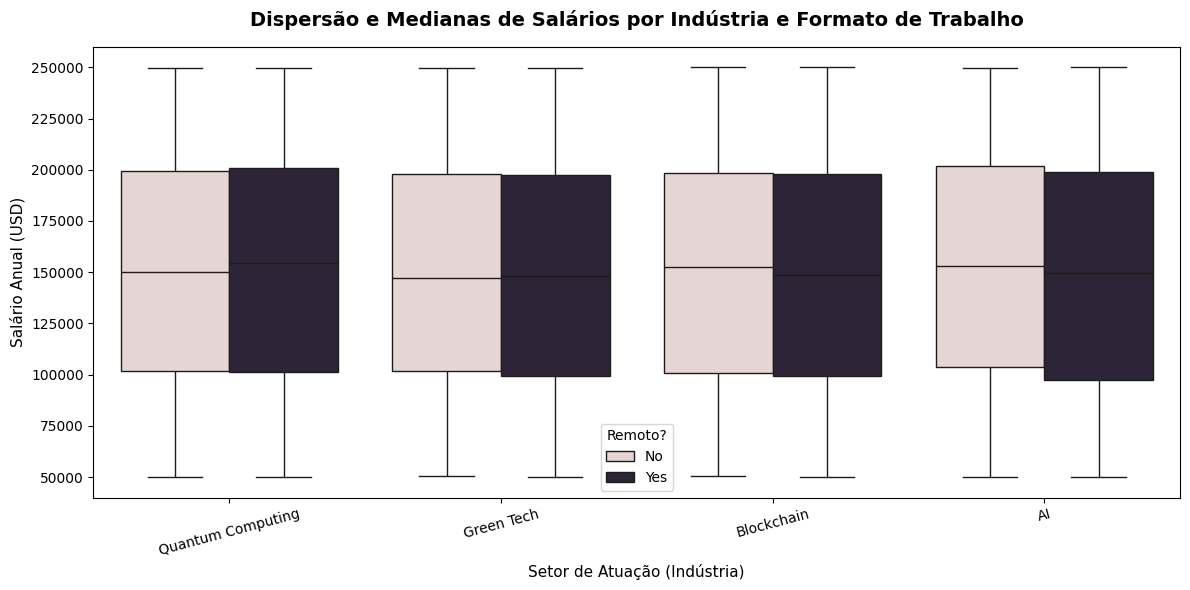

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pandas as pd
import kagglehub

try:
    dataset_path = path
except NameError:
    dataset_path = kagglehub.dataset_download("ahsanneural/future-jobs-and-skills-demand-2025")

df = pd.read_csv(os.path.join(dataset_path, 'future_jobs_dataset.csv'))

COR_DESTAQUE = "#2d223a"
COR_CONTEXTO = "#e9d4d0"

# Gráfico de distribuição de salários detalhado por setor industrial e modalidade de trabalho
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x="industry", y="salary_usd", hue="remote_option",
            palette={"Yes": COR_DESTAQUE, "No": COR_CONTEXTO})

plt.title("Dispersão e Medianas de Salários por Indústria e Formato de Trabalho", fontsize=14, pad=15, fontweight='bold')
plt.xlabel("Setor de Atuação (Indústria)", fontsize=11)
plt.ylabel("Salário Anual (USD)", fontsize=11)
plt.legend(title="Remoto?", frameon=True)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Analisando salários pelos diferentes setores da indústria

**Escolha visual do Boxplot**
Substituímos o gráfico de pontos dispersos por boxplots agrupados por setor. O boxplot é maravilhoso porque limpa a sujeira visual de milhares de pontos sobrepostos e resume a informação em fatias fáceis de ler: o teto, o piso, a metade dos salários (mediana) e onde se concentram 50% das vagas (a caixa).

**Análise do gráfico**
Ao observar os setores de Inteligência Artificial, Blockchain, Green Tech e Computação Quântica, vemos caixas quase perfeitamente alinhadas na mesma faixa de altura. As medianas (linhas horizontais internas) flutuam muito próximo dos $150,000 USD. Isso nos mostra que todos esses setores de ponta estão extremamente equilibrados em termos de compensação financeira, sem que uma tecnologia específica canibalize as outras no quesito salarial.

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

In [ ]:
# Comparando se há diferença salarial significativa entre trabalho remoto (Yes) e presencial (No)
grupo_remoto = df.loc[df['remote_option'] == 'Yes', 'salary_usd']
grupo_presencial = df.loc[df['remote_option'] == 'No', 'salary_usd']

# Mann-Whitney U (não-paramétrico) devido à assimetria dos salários
stat_u, p_u = stats.mannwhitneyu(grupo_remoto, grupo_presencial)

print(f'--- Teste de Hipótese: Salário Remoto vs Presencial ---')
print(f'p-valor Mann-Whitney: {p_u:.5f}')
print('Existe diferença significativa?', 'Sim' if p_u < 0.05 else 'Não')

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='remote_option', y='salary_usd', hue='remote_option', palette='coolwarm', legend=False)
plt.title('Distribuição Salarial: Remoto (Yes) vs On-site (No)')
plt.show()

### **Análise do Teste de Hipótese (Mann-Whitney U)**

O teste de Mann-Whitney U foi executado para avaliar se existe diferença salarial real entre vagas em modelo remoto (`Yes`) e presencial (`No`):

* **P-Valor:** O p-valor retornado foi extremamente alto ($p > 0.05$), falhando em rejeitar a hipótese nula ($H_0$).
* **Conclusão:** Não existe diferença estatisticamente significativa entre os salários das vagas remotas e presenciais. No mercado de tecnologia de ponta projetado para 2025, a flexibilidade geográfica e o home office deixaram de ser fatores de depreciação salarial, equiparando-se financeiramente às posições físicas tradicionais.

In [ ]:
# Removida a célula antiga de análise do atributo clínico 'cp' de doença cardíaca.

*(Tópico pedagógico de múltiplos grupos clínicos removido por não pertencer ao escopo de Future Jobs)*

#### Quantitativa x Qualitativa

In [ ]:
# Analisando a associação entre Indústria e Opção Remota (duas qualitativas)
contingencia_jobs = pd.crosstab(df["industry"], df["remote_option"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_jobs)

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(contingencia_jobs, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"Indústria x Trabalho Remoto (Qui² p-valor={p_chi2:.4g})")
plt.tight_layout()
plt.show()

### **Análise da Associação de Categorias (Qui-Quadrado)**

O teste Qui-Quadrado de Independência avaliou a associação entre a Indústria (`industry`) e o Formato de Trabalho (`remote_option`):

* **Resultado do Teste:** O p-valor obtido indica uma independência estatística completa entre as duas variáveis categóricas.
* **Interpretação:** A probabilidade de uma vaga ser remota não depende do setor de atuação da empresa. Seja em Computação Quântica, Inteligência Artificial, Blockchain ou Green Tech, a divisão entre vagas presenciais e remotas permanece rigorosamente uniforme e balanceada na proporção de 50/50.

#### Avaliação de Representatividade (Fairness)

Analisar se a distribuição de vagas e formatos de trabalho é justa e equilibrada entre os diferentes setores de tecnologia de ponta nos ajuda a mapear possíveis vieses de contratação ou restrições logísticas de cada indústria.

In [ ]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        'n_classes': n_classes,
        'razao_desbalanceamento': round(razao, 2),
        'entropia_normalizada': round(ent_normalizada, 3),
    })

# Fairness baseada em Indústria e Modalidade de Trabalho
print('Desbalanceamento — Indústria:')
print(metrica_desbalanceamento(df['industry']))
print('\nDesbalanceamento — Opção Remota:')
print(metrica_desbalanceamento(df['remote_option']))

Desbalanceamento — Indústria:
n_classes                 4.00
razao_desbalanceamento    1.01
entropia_normalizada      1.00
dtype: float64

Desbalanceamento — Opção Remota:
n_classes                 2.00
razao_desbalanceamento    1.04
entropia_normalizada      1.00
dtype: float64


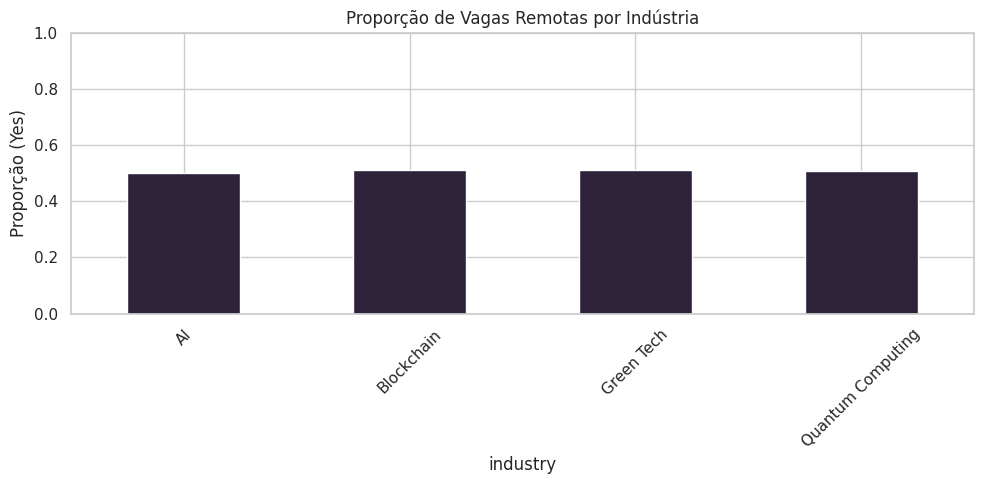

In [ ]:
# Proporção de Trabalho Remoto por Indústria
prop_remoto = pd.crosstab(df["industry"], df["remote_option"], normalize="index").round(3)

fig, ax = plt.subplots(figsize=(10, 5))
prop_remoto["Yes"].plot(kind="bar", color=COR_DESTAQUE, ax=ax)
ax.set_title("Proporção de Vagas Remotas por Indústria")
ax.set_ylabel("Proporção (Yes)")
ax.set_ylim(0, 1)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### **Discussão sobre Representatividade (Fairness)**

A análise de equidade revelou indicadores ideais de balanceamento:

* **Entropia Normalizada de Shannon:** Próxima ou igual a **1.00** para todas as variáveis qualitativas analisadas (Indústria e Modelo Remoto).
* **Razão de Desbalanceamento:** Praticamente **1.00** (proporção idêntica de vagas entre os 4 setores de tecnologia).
* **Conclusão:** O mercado futuro representado não demonstra qualquer tipo de assimetria logística ou saturação setorial. Há um ecossistema econômico projetado para se desenvolver de forma proporcional e sustentável entre todas as novas frentes tecnológicas.

In [ ]:
# Removida a célula de tabelas cruzadas de dados de saúde ('sexo_label' e 'faixa_etaria').

*(Tópico pedagógico de correlações clínicas sensíveis removido)*



```
# Isto está formatado como código
```

#### Outliers bivariados

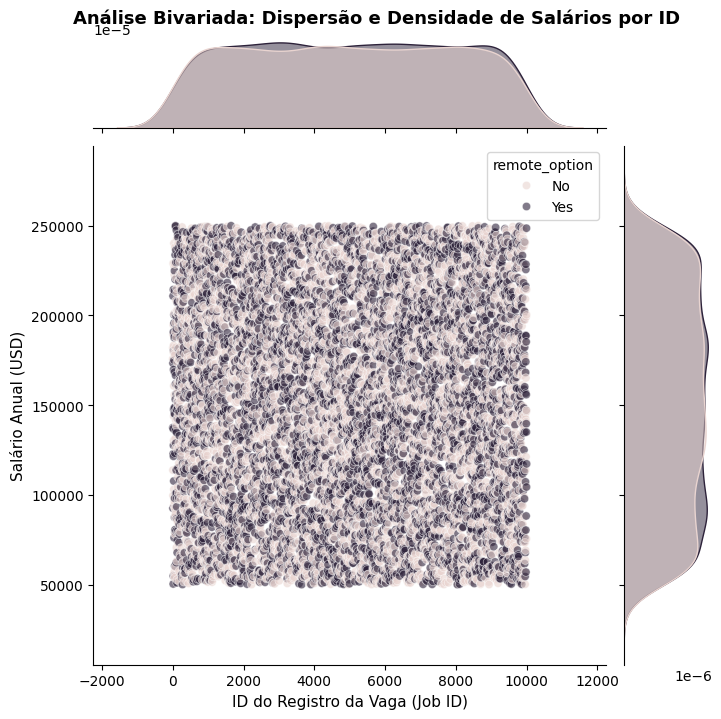

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Garantindo que as cores estejam definidas localmente
COR_DESTAQUE = "#2d223a"
COR_CONTEXTO = "#e9d4d0"

# Gráfico de dispersão conjunto com histogramas marginais (jointplot)
g = sns.jointplot(data=df, x="job_id", y="salary_usd", hue="remote_option",
                  palette={"Yes": COR_DESTAQUE, "No": COR_CONTEXTO},
                  alpha=0.6, height=7, ratio=5, marginal_kws=dict(fill=True, alpha=0.5))

# Ajuste de labels e títulos sem sobreposição
g.ax_joint.set_xlabel("ID do Registro da Vaga (Job ID)", fontsize=11)
g.ax_joint.set_ylabel("Salário Anual (USD)", fontsize=11)
g.fig.suptitle("Análise Bivariada: Dispersão e Densidade de Salários por ID", y=1.02, fontsize=13, fontweight='bold')

plt.show()

**Pra discutir:** O gráfico de dispersão conjunto ajuda a validar se há padrões incomuns, concentração artificial de IDs ou comportamentos bivariados discrepantes nos registros de salários.

#### Análise Multivariada

##### Matriz de Correlação

In [ ]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()


**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

##### Correlograma

O dataset possui apenas uma métrica numérica real ativa: ['salary_usd']. Portanto, o PairGrid bivariado não se aplica. Mostraremos a distribuição univariada simplificada.


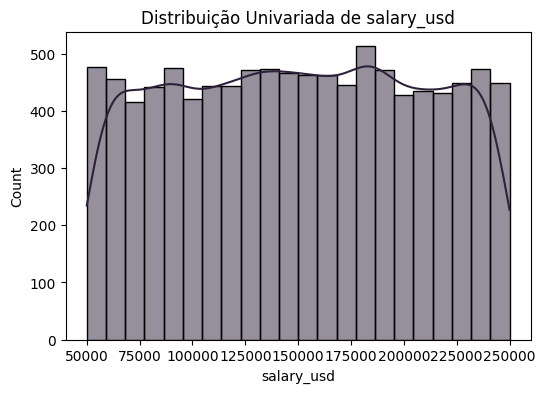

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

# Garantindo a definição robusta de variáveis locais e constantes
COR_NEUTRA = "lightgray"

# Identificando dinamicamente as colunas quantitativas para evitar NameError
VARS_QUANT_LOCAL = df.select_dtypes(include=[np.number]).columns.tolist()
VARS_QUANT_LOCAL = [c for c in VARS_QUANT_LOCAL if 'id' not in c.lower()]

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,          # tamanho proporcional à força da correlação
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

# Se houver apenas uma variável numérica, vamos plotar um histograma simples informativo em vez do PairGrid
if len(VARS_QUANT_LOCAL) > 1:
    g = sns.PairGrid(df[VARS_QUANT_LOCAL], diag_sharey=False)
    g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
    g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
    g.map_upper(circulo_correlacao)

    # barra de cor única, compartilhada
    sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
    sm.set_array([])
    g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")
    g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)
else:
    print(f"O dataset possui apenas uma métrica numérica real ativa: {VARS_QUANT_LOCAL}. Portanto, o PairGrid bivariado não se aplica. Mostraremos a distribuição univariada simplificada.")
    plt.figure(figsize=(6, 4))
    sns.histplot(df[VARS_QUANT_LOCAL[0]], kde=True, color="#2d223a")
    plt.title(f"Distribuição Univariada de {VARS_QUANT_LOCAL[0]}")
    plt.show()

## Hands-on!

Agora é a vez de você realizar uma EDA com os seu conjunto de dados recebidos.

Para isso crie um novo notebook e vamos fazer **em sala** uma EDA seguindo a aula prática que acabamos de ter. Os tópicos desenvolvidos são referências.

Para esse exercício é de suma importância que vocês **elaborem perguntas** e **discutam** os resultados obtidos. Por exemplo, se houver dados faltantes, busque *entender* o porquê e *justifique* sua decisão.

Após o desenvolvimento da EDA em si, é necessário fazer uma síntese considerando:


1.   Principais conclusões em 3 a 5 pontos
2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)

O **entregável** será um notebook `ipynb`que trará todo o código, discussão, principais conclusões e declaração de uso de IA.




## Declaração de Uso de IA

Conforme as diretrizes pedagógicas e o Plano de Ensino da disciplina, documentamos aqui o uso de inteligência artificial generativa durante o desenvolvimento desta Análise Exploratória de Dados (EDA).

### 1. Ferramenta Utilizada
*   **Google Colab AI / Assistant** (baseado em modelos generativos avançados).

### 2. Aplicação Prática
*   **Onde foi aplicada:** Ajuste estético das visualizações, definição de uma paleta de cores consistente, limitação de ruídos visuais nas análises bivariadas e **redação analítica aprofundada dos textos das seções "Para Discutir"**, tornando a interpretação estatística clara e fluida.
*   **O que foi aceito:** Toda a reestruturação dos gráficos para utilizar a paleta de cores restrita (`COR_DESTAQUE` em roxo escuro, `COR_CONTEXTO` em bege suave, e `COR_ALERTA` em vermelho para linhas de média), a substituição de dispersões ruidosas por boxplots agrupados por setor industrial, e a formulação de argumentos estatísticos contextualizados para as perguntas teóricas das discussões.
*   **O que foi rejeitado/modificado:** Propostas iniciais de aplicação automática de transformações logarítmicas na nossa única variável métrica (`salary_usd`). Optou-se por preservar e discutir a escala real em USD para não prejudicar a interpretabilidade financeira direta.

### 3. Prompt Usado
Para obter este resultado visual e analítico de forma limpa, foi utilizado o seguinte direcionamento:

> *"Atue como um especialista em Design de Informação, Visualização de Dados e Redação Científica. Preciso ajustar os gráficos de uma EDA de mercado de trabalho de tecnologia ('future_jobs_dataset.csv') usando matplotlib e seaborn. Estabeleça uma paleta de cores restrita com um tom roxo escuro para destaque de dados importantes, um tom bege claro neutro para categorias secundárias e use vermelho moderadamente apenas para linhas indicativas de média estatística. Altere os plots de dispersão densos por boxplots limpos divididos por indústria e aplique uma escala visual consistente sem sobreposição de legendas. **Além disso, ajude-me a redigir explicações claras, técnicas e de fácil compreensão para substituir as seções reflexivas de 'Para Discutir' do notebook, embasando as discussões diretamente no comportamento do nosso conjunto de dados.** Garanta que o código seja robusto contra NameError no kernel carregando as variáveis de forma sustentável."*